In [3]:
import numpy as np
import h2py
import moments 
import matplotlib.pyplot as plt 
import matplotlib as mpl
import copy
import msprime
import demes 
import demesdraw
import pandas
from matplotlib.transforms import ScaledTranslation


mpl.rc("xtick", labelsize=7)
mpl.rc("ytick", labelsize=7)
mpl.rc("font", size=8)
mpl.rc("axes", labelsize=8)
mpl.rc("axes", titlesize=8)
mpl.rc("legend", fontsize=7)
mpl.rc("axes", titlesize="small")

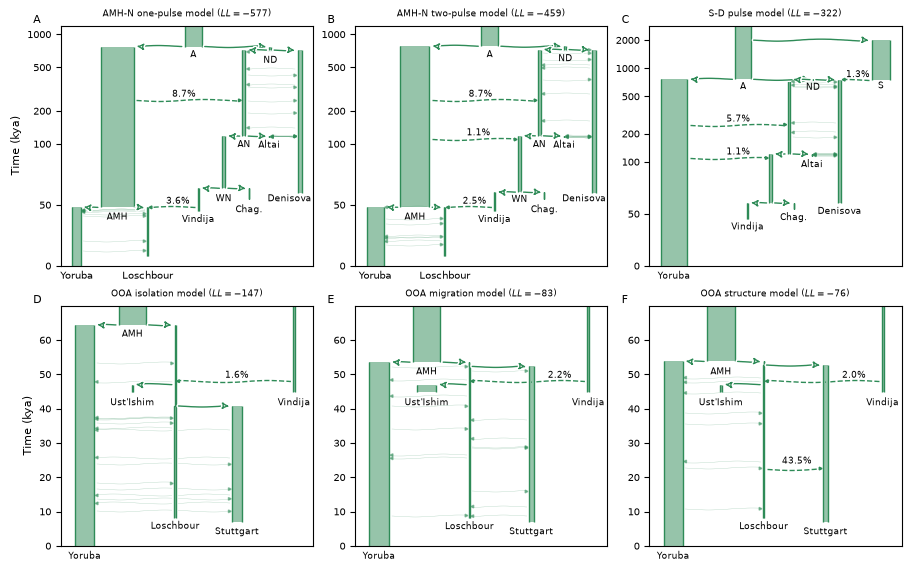

In [5]:

def plot_hn_one_pulse_model(ax):
    fname = "../../all_models/main_models/bherer_amh_nea_one_pulse.yaml"
    graph = demes.load(fname)
    pops = [
        "Yoruba1",
        "Loschbour",
        "Vindija",
        "Chagyrskaya", 
        "Altai",
        "Denisova",
        "MH", 
        "WN",
        "N",
        "ND",
        "Anc"
    ]
    positions = {x: positions0[x] for x in pops}
    demesdraw.tubes(
        graph,
        ax=ax,
        labels=None,
        inf_ratio=0.40,
        log_time=False,
        positions=positions,
        colours=graph_color,
        num_lines_per_migration=4
    )
    ax.spines["top"].set_visible(True)
    ax.spines["right"].set_visible(True)
    ax.spines["bottom"].set_visible(True)
    label_positions = {
        "Vindija": (positions["Vindija"], 3.6e4),
        "Chag.": (positions["Chagyrskaya"], 4.4e4),
        "Altai": (positions["Altai"], 9.7e4),
        "Denisova": (positions["Denisova"]-1e4, 5.3e4),
        #"Loschbour": (positions["Loschbour"], 2e3),
        "A": (positions["Anc"], 6.2e5),
        "AN": (positions["N"], 9.75e4),
        "WN": (positions["WN"], 5.31e4),
        "ND": (positions["ND"], 5.5e5),
        "AMH": (positions["MH"], 3.8e4),
    }
    for label, (x, y) in label_positions.items():
        ax.text(x, y, label, horizontalalignment="center", fontsize="small")
    pulse_annotations = {        
        "3.6%": (9e4, 5.1e4),
        "8.7%": (9.6e4, 2.7e5)
    }
    for label, (x, y) in pulse_annotations.items():
        ax.text(x, y, label, horizontalalignment="center", fontsize="small")
    ax.set_xticks([positions["Yoruba1"], positions["Loschbour"]], ["Yoruba", "Loschbour"])
    ax.set_yscale("symlog", linthresh=1e5)
    ax.set_ylabel("Time (kya)")
    yticks = [0, 5e4, 1e5, 2e5, 5e5, 1e6]
    ax.set_yticks(yticks, np.array(yticks).astype(np.int64) // 1000)
    return


def plot_hn_two_pulse_model(ax):
    fname = "../../all_models/main_models/bherer_amh_nea_two_pulse.yaml"
    graph = demes.load(fname)
    pops = [
        "Yoruba1",
        "Loschbour",
        "Vindija",
        "Chagyrskaya", 
        "Altai",
        "Denisova",
        "MH", 
        "WN",
        "N",
        "ND",
        "Anc"
    ]
    positions = {x: positions0[x] for x in pops}
    demesdraw.tubes(
        graph,
        ax=ax,
        labels=None,
        inf_ratio=0.40,
        log_time=False,
        positions=positions,
        colours=graph_color,
        num_lines_per_migration=4
    )
    ax.spines["top"].set_visible(True)
    ax.spines["right"].set_visible(True)
    ax.spines["bottom"].set_visible(True)
    label_positions = {
        "Vindija": (positions["Vindija"], 3.6e4),
        "Chag.": (positions["Chagyrskaya"], 4.4e4),
        "Altai": (positions["Altai"], 9.7e4),
        "Denisova": (positions["Denisova"]-1e4, 5.3e4),
        #"Loschbour": (positions["Loschbour"], 2e3),
        "A": (positions["Anc"], 6.2e5),
        "AN": (positions["N"], 9.75e4),
        "WN": (positions["WN"], 5.25e4),
        "ND": (positions["ND"], 5.7e5),
        "AMH": (positions["MH"], 3.8e4),
    }
    for label, (x, y) in label_positions.items():
        ax.text(x, y, label, horizontalalignment="center", fontsize="small")
    pulse_annotations = {
        "2.5%": (9e4, 5.1e4),
        "1.1%": (9.4e4, 1.2e5),
        "8.7%": (9.6e4, 2.7e5)
    }
    for label, (x, y) in pulse_annotations.items():
        ax.text(x, y, label, horizontalalignment="center", fontsize="small")
    ax.set_xticks([positions["Yoruba1"], positions["Loschbour"]], ["Yoruba", "Loschbour"])
    ax.set_yscale("symlog", linthresh=1e5)
    ax.set_ylabel("Time (kya)")
    yticks = [0, 5e4, 1e5, 2e5, 5e5, 1e6]
    ax.set_yticks(yticks, np.array(yticks).astype(np.int64) // 1000)
    return


def plot_s_d_pulse_model(ax):
    fname = "../../all_models/edited_models/bherer_sup_den_edited.yaml"
    graph = demes.load(fname)
    pops = [
        "Anc",
        "Sup",
        "Yoruba1",
        "WN",
        "N", 
        "ND",
        "Vindija",
        "Chagyrskaya",
        "Altai",
        "Denisova"
    ]
    positions = {x: positions0[x] for x in pops}
    positions["Yoruba1"] = 3e4
    demesdraw.tubes(
        graph,
        ax=ax,
        labels=None,
        inf_ratio=0.30,
        positions=positions,
        colours=graph_color,
        num_lines_per_migration=4,
    )
    ax.spines["top"].set_visible(True)
    ax.spines["right"].set_visible(True)
    ax.spines["bottom"].set_visible(True)
    # annotate demes
    label_positions = {
        "Vindija": (positions["Vindija"], 3.5e4),
        "Chag.": (positions["Chagyrskaya"], 4.4e4),
        "Altai": (positions["Altai"], 9.5e4),
        "Denisova": (positions["Denisova"], 5e4),
        "A": (positions["Anc"], 6e5),
        "S": (positions["Sup"], 6.1e5),
        #"AN": (positions["N"], 9.7e4),
        #"WN": (positions["WN"], 5.2e4),
        "ND": (positions["ND"], 5.9e5),
    }
    for label, (x, y) in label_positions.items():
        ax.text(x, y, label, horizontalalignment="center", fontsize="small")
    ax.set_xticks([positions["Yoruba1"]], ["Yoruba"], fontsize="small")
    pulse_annotations = {
        "1.1%": (1e5, 1.2e5),
        "5.7%": (1e5, 2.7e5),
        "1.3%": (2.3e5, 8.05e5),
    }
    for label, (x, y) in pulse_annotations.items():
        ax.text(x, y, label, horizontalalignment="center", fontsize="small")
    ax.set_yscale("symlog", linthresh=1e5)
    ax.set_ylabel("Time (kya)")
    yticks = [0, 5e4, 1e5, 2e5, 5e5, 1e6, 2e6]
    ax.set_yticks(yticks, np.array(yticks).astype(np.int64) // 1000)
    return
    

def plot_ooa_isolation_model(ax):
    fname = "../../all_models/main_models/edited_bherer_los_stu_isolation.yaml"
    graph = demes.load(fname)
    pops = [
        "Anc",
        "MH",
        "Yoruba1",
        "Loschbour",
        "Stuttgart", 
        "Vindija",
        "UstIshim"
    ]
    positions = {
        "Yoruba1": -1e4,
        "Stuttgart": 145000,
        "Loschbour": 100000,
        "UstIshim": 40000,
        "Vindija": 1.85e5,
        "Chagyrskaya": 1.5e5, 
        "Altai": 1.8e5,
        "Denisova": 2.1e5,
        "Sup": 2.4e5,
        "MH": 4e4, 
        "WN": 1.35e5,
        "N": 1.55e5,
        "ND": 1.81e5,
        "Anc": 1.05e5,
        "OOA": 75000,
    }
    _positions = {x: positions1[x] for x in pops}
    demesdraw.tubes(
        graph,
        ax=ax,
        labels=None,
        positions=_positions,
        colours=graph_color,
        num_lines_per_migration=4
    )
    ax.spines["top"].set_visible(True)
    ax.spines["right"].set_visible(True)
    ax.spines["bottom"].set_visible(True)
    yticks = [0, 10, 20, 30, 40, 50, 60]
    ax.set_yticks(np.array(yticks) * 1e3, yticks)
    ax.set_ylabel("Time (kya)")
    ax.set_xticks([_positions["Yoruba1"]], ["Yoruba"], fontsize="small")
    label_positions = {
        "Vindija": (_positions["Vindija"], 4.1e4),
        "Loschbour": (_positions["Loschbour"], 5e3),
        "Stuttgart": (_positions["Stuttgart"], 3.4e3),
        "Ust'Ishim":  (_positions["UstIshim"], 4.1e4),
        "AMH": (_positions["MH"], 6.1e4),
    }
    for label, (x, y) in label_positions.items():
        ax.text(x, y, label, horizontalalignment="center", fontsize="small")

    pulse_annotations = {
        "1.6%": (150000, 4.9e4),
    }
    for label, (x, y) in pulse_annotations.items():
        ax.text(x, y, label, horizontalalignment="center", fontsize="small")
    ax.set_ylim(0, 6.5e4)
    ax.set_xlim(-3.5e4, 2.3e5)
    return

    
def plot_ooa_mig_model(ax):
    fname = "../../all_models/main_models/edited_bherer_los_stu_migration.yaml"
    graph = demes.load(fname)
    pops = [
        "Anc",
        "MH",
        "Yoruba1",
        "Loschbour",
        "Stuttgart", 
        "Vindija",
        "UstIshim",
    ]
    # map deme names to desired labels
    _positions = {x: positions1[x] for x in pops}
    demesdraw.tubes(
        graph,
        ax=ax,
        labels=None,
        positions=_positions,
        colours=graph_color,
        num_lines_per_migration=4
    )
    ax.spines["top"].set_visible(True)
    ax.spines["right"].set_visible(True)
    ax.spines["bottom"].set_visible(True)
    yticks = [0, 10, 20, 30, 40, 50, 60]
    ax.set_yticks(np.array(yticks) * 1e3, yticks)
    ax.set_ylabel("Time (kya)")

    ax.set_xticks([_positions["Yoruba1"]], ["Yoruba"], fontsize="small")
    label_positions = {
        "Vindija": (_positions["Vindija"], 4.1e4),
        "Loschbour": (_positions["Loschbour"], 4.9e3),
        "Stuttgart": (_positions["Stuttgart"], 3.4e3),
        "Ust'Ishim":  (_positions["UstIshim"], 4.1e4),
        "AMH": (_positions["MH"], 5e4)
    }
    for label, (x, y) in label_positions.items():
        ax.text(x, y, label, horizontalalignment="center", fontsize="small")
    
    pulse_annotations = {
        "2.2%": (180000, 4.9e4),
    }
    for label, (x, y) in pulse_annotations.items():
        ax.text(x, y, label, horizontalalignment="center", fontsize="small")

    ax.set_ylim(0, 6.5e4)
    ax.set_xlim(-3.5e4, 2.3e5)
    return

def plot_ooa_pulse_model(ax):
    fname = "../../all_models/main_models/edited_bherer_los_stu_admixture.yaml"
    graph = demes.load(fname)
    pops = [
        "Anc",
        "MH",
        "Yoruba1",
        "Loschbour",
        "Stuttgart", 
        "Vindija",
        "UstIshim",
        "BE"
    ]
    # map deme names to desired labels
    _positions = {x: positions1[x] for x in pops}
    demesdraw.tubes(
        graph,
        ax=ax,
        labels=None,
        positions=_positions,
        colours=graph_color,
        num_lines_per_migration=4
    )
    ax.spines["top"].set_visible(True)
    ax.spines["right"].set_visible(True)
    ax.spines["bottom"].set_visible(True)
    yticks = [0, 10, 20, 30, 40, 50, 60]
    ax.set_yticks(np.array(yticks) * 1e3, yticks)
    ax.set_ylabel("Time (kya)")

    ax.set_xticks([_positions["Yoruba1"]], ["Yoruba"], fontsize="small")
    label_positions = {
        "Vindija": (_positions["Vindija"], 4.1e4),
        "Loschbour": (_positions["Loschbour"], 4.9e3),
        "Stuttgart": (_positions["Stuttgart"], 3.4e3),
        "Ust'Ishim":  (_positions["UstIshim"], 4.1e4),
        "AMH": (_positions["MH"], 5e4)
    }
    for label, (x, y) in label_positions.items():
        ax.text(x, y, label, horizontalalignment="center", fontsize="small")
    
    pulse_annotations = {
        "2.0%": (180000, 4.9e4),
        "43.5%": (120000, 2.4e4),
    }
    for label, (x, y) in pulse_annotations.items():
        ax.text(x, y, label, horizontalalignment="center", fontsize="small")

    ax.set_ylim(0, 6.5e4)
    ax.set_xlim(-3.5e4, 2.3e5)
    return


positions0 = {
    "Yoruba1": -1e4,
    "Stuttgart": 9e4,
    "Loschbour": 6e4,
    "UstIshim": 3e4,
    "Vindija": 1.1e5,
    "Chagyrskaya": 1.6e5, 
    "Altai": 1.8e5,
    "Denisova": 2.1e5,
    "Sup": 2.55e5,
    "MH": 3e4, 
    "WN": 1.35e5,
    "N": 1.55e5,
    "ND": 1.81e5,
    "Anc": 1.05e5
}

positions1 = {
    "Yoruba1": -1e4,
    "Stuttgart": 150000,
    "Loschbour": 85000,
    "UstIshim": 40000,
    "Vindija": 2.1e5,
    "Chagyrskaya": 1.5e5, 
    "Altai": 1.8e5,
    "MH": 4e4, 
    "WN": 1.35e5,
    "N": 1.55e5,
    "ND": 1.81e5,
    "Anc": 1.05e5,
    "BE": 1.8e5
}


graph_color = "seagreen"
mosaic = "ABC;DEF"
fig, axs = plt.subplot_mosaic(mosaic, figsize=(9, 5.6), layout="constrained")


plot_hn_one_pulse_model(axs["A"])
axs["A"].set_title("AMH-N one-pulse model ($LL=-577$)")
axs["A"].set_ylim(0, 1.2e6)

plot_hn_two_pulse_model(axs["B"])
axs["B"].set_title("AMH-N two-pulse model ($LL=-459$)")
axs["B"].set_ylim(0, 1.2e6)

plot_s_d_pulse_model(axs["C"])
axs["C"].set_title("S-D pulse model ($LL=-322$)")
#axs["C"].set_ylim(0, 2.5e6)


plot_ooa_isolation_model(axs["D"])
axs["D"].set_title("OOA isolation model ($LL=-147$)")
axs["D"].set_ylim(0, 7e4)

plot_ooa_mig_model(axs["E"])
axs["E"].set_title("OOA migration model ($LL=-83$)")
axs["E"].set_ylim(0, 7e4)

plot_ooa_pulse_model(axs["F"])
axs["F"].set_title("OOA structure model ($LL=-76$)")
axs["F"].set_ylim(0, 7e4)

for lab in axs:
    if lab in ("A", "D"):
        axs[lab].set_ylabel("Time (kya)")
    else:
        axs[lab].set_ylabel(None)


for label, ax in axs.items():
    ax.text(0.0, 1.0, label, fontsize="medium", va="bottom", transform=(
        ax.transAxes + ScaledTranslation(-20/72, +0/72, fig.dpi_scale_trans)))
    
plt.savefig("../../figures/submodels.pdf")

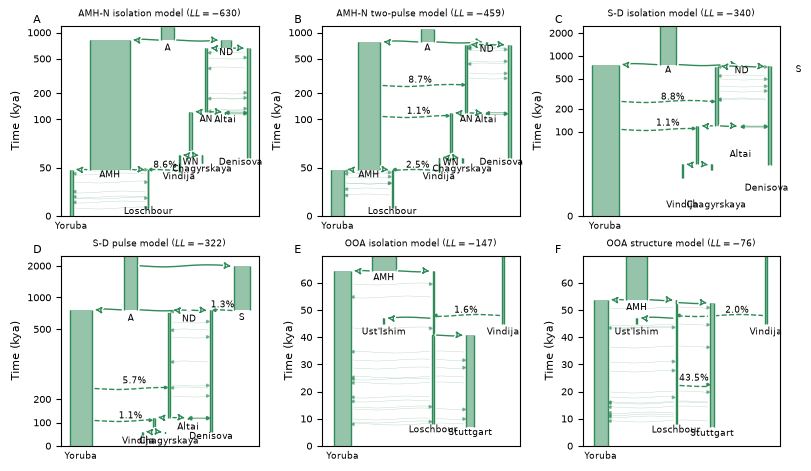

In [11]:
# Older arrangement
def plot_hn_zero_pulse_model(ax):
    fname = "../../all_models/main_models/bherer_amh_nea_no_pulse.yaml"
    graph = demes.load(fname)
    positions = {
        "Yoruba1": -2e4,
        "Loschbour": 8e4,
        "UstIshim": 3e4,
        "Vindija": 1.2e5,
        "Chagyrskaya": 1.5e5, 
        "Altai": 1.8e5,
        "Denisova": 2.1e5,
        "Sup": 2.4e5,
        "MH": 3e4, 
        "WN": 1.35e5,
        "N": 1.55e5,
        "ND": 1.81e5,
        "Anc": 1.05e5
    }
    pops = [
        "Yoruba1",
        "Loschbour",
        "Vindija",
        "Chagyrskaya", 
        "Altai",
        "Denisova",
        "MH", 
        "WN",
        "N",
        "ND",
        "Anc"
    ]
    demesdraw.tubes(
        graph,
        ax=ax,
        labels=None,
        inf_ratio=0.30,
        log_time=False,
        positions={x: positions[x] for x in pops},
        colours=graph_color,
        num_lines_per_migration=4
    )
    ax.spines["top"].set_visible(True)
    ax.spines["right"].set_visible(True)
    ax.spines["bottom"].set_visible(True)
    label_positions = {
        "Vindija": (positions["Vindija"], 3.8e4),
        "Chagyrskaya": (positions["Chagyrskaya"], 4.6e4),
        "Altai": (positions["Altai"], 9.7e4),
        "Denisova": (positions["Denisova"]-1e4, 5.3e4),
        "Loschbour": (positions["Loschbour"], 2e3),
        "A": (positions["Anc"], 6.2e5),
        "AN": (positions["N"], 9.75e4),
        "WN": (positions["WN"], 5.31e4),
        "ND": (positions["ND"], 5.5e5),
        "AMH": (positions["MH"], 4e4),
    }
    for label, (x, y) in label_positions.items():
        ax.text(x, y, label, horizontalalignment="center", fontsize="small")
    pulse_annotations = {
        "8.6%": (1.02e5, 5e4),
    }
    for label, (x, y) in pulse_annotations.items():
        ax.text(x, y, label, horizontalalignment="center", fontsize="small")
    ax.set_xticks([positions["Yoruba1"]], ["Yoruba"], fontsize="small")
    ax.set_yscale("symlog", linthresh=1e5)
    ax.set_ylabel("Time (kya)")
    yticks = [0, 5e4, 1e5, 2e5, 5e5, 1e6]
    ax.set_yticks(yticks, np.array(yticks).astype(np.int64) // 1000)
    return


def plot_hn_two_pulse_model(ax):
    fname = "../../all_models/main_models/bherer_amh_nea_two_pulse.yaml"
    graph = demes.load(fname)
    positions = {
        "Yoruba1": -1e4,
        "Stuttgart": 9e4,
        "Loschbour": 6e4,
        "UstIshim": 3e4,
        "Vindija": 1.2e5,
        "Chagyrskaya": 1.5e5, 
        "Altai": 1.8e5,
        "Denisova": 2.1e5,
        "Sup": 2.4e5,
        "MH": 3e4, 
        "WN": 1.35e5,
        "N": 1.55e5,
        "ND": 1.81e5,
        "Anc": 1.05e5
    }
    pops = [
        "Yoruba1",
        "Loschbour",
        "Vindija",
        "Chagyrskaya", 
        "Altai",
        "Denisova",
        "MH", 
        "WN",
        "N",
        "ND",
        "Anc"
    ]
    demesdraw.tubes(
        graph,
        ax=ax,
        labels=None,
        inf_ratio=0.30,
        log_time=False,
        positions={x: positions[x] for x in pops},
        colours=graph_color,
        num_lines_per_migration=4
    )
    ax.spines["top"].set_visible(True)
    ax.spines["right"].set_visible(True)
    ax.spines["bottom"].set_visible(True)
    label_positions = {
        "Vindija": (positions["Vindija"], 3.8e4),
        "Chagyrskaya": (positions["Chagyrskaya"], 4.6e4),
        "Altai": (positions["Altai"], 9.7e4),
        "Denisova": (positions["Denisova"]-1e4, 5.3e4),
        "Loschbour": (positions["Loschbour"], 2e3),
        "A": (positions["Anc"], 6.2e5),
        "AN": (positions["N"], 9.75e4),
        "WN": (positions["WN"], 5.25e4),
        "ND": (positions["ND"], 6e5),
        "AMH": (positions["MH"], 4e4),
    }
    for label, (x, y) in label_positions.items():
        ax.text(x, y, label, horizontalalignment="center", fontsize="small")
    pulse_annotations = {
        "2.5%": (9.3e4, 5e4),
        "1.1%": (9.4e4, 1.16e5),
        "8.7%": (9.6e4, 2.65e5)
    }
    for label, (x, y) in pulse_annotations.items():
        ax.text(x, y, label, horizontalalignment="center", fontsize="small")
    ax.set_xticks([positions["Yoruba1"]], ["Yoruba"], fontsize="small")
    ax.set_yscale("symlog", linthresh=1e5)
    ax.set_ylabel("Time (kya)")
    yticks = [0, 5e4, 1e5, 2e5, 5e5, 1e6]
    ax.set_yticks(yticks, np.array(yticks).astype(np.int64) // 1000)
    return



def plot_ooa_isolation_model(ax):
    fname = "../../all_models/main_models/bherer_los_stu_isolation.yaml"
    graph = demes.load(fname)
    pops = [
        "Anc",
        "MH",
        "Yoruba1",
        "Loschbour",
        "Stuttgart", 
        "Vindija",
        "UstIshim"
    ]
    positions = {
        "Yoruba1": -1e4,
        "Stuttgart": 145000,
        "Loschbour": 100000,
        "UstIshim": 40000,
        "Vindija": 1.85e5,
        "Chagyrskaya": 1.5e5, 
        "Altai": 1.8e5,
        "Denisova": 2.1e5,
        "Sup": 2.4e5,
        "MH": 4e4, 
        "WN": 1.35e5,
        "N": 1.55e5,
        "ND": 1.81e5,
        "Anc": 1.05e5,
        "OOA": 75000,
    }
    _positions = {x: positions[x] for x in pops}
    demesdraw.tubes(
        graph,
        ax=ax,
        labels=None,
        positions=_positions,
        colours=graph_color,
        num_lines_per_migration=4
    )
    ax.spines["top"].set_visible(True)
    ax.spines["right"].set_visible(True)
    ax.spines["bottom"].set_visible(True)
    yticks = [0, 10, 20, 30, 40, 50, 60]
    ax.set_yticks(np.array(yticks) * 1e3, yticks)
    ax.set_ylabel("Time (kya)")
    ax.set_xticks([_positions["Yoruba1"]], ["Yoruba"], fontsize="small")
    label_positions = {
        "Vindija": (_positions["Vindija"], 4.1e4),
        "Loschbour": (_positions["Loschbour"], 5e3),
        "Stuttgart": (_positions["Stuttgart"], 4e3),
        "Ust'Ishim":  (_positions["UstIshim"], 4.1e4),
        "AMH": (_positions["MH"], 6.1e4),
    }
    for label, (x, y) in label_positions.items():
        ax.text(x, y, label, horizontalalignment="center", fontsize="small")

    pulse_annotations = {
        "1.6%": (140000, 4.9e4),
    }
    for label, (x, y) in pulse_annotations.items():
        ax.text(x, y, label, horizontalalignment="center", fontsize="small")
    ax.set_ylim(0, 6.5e4)
    ax.set_xlim(-3.5e4, 2.05e5)
    return


def plot_ooa_pulse_model(ax):
    fname = "../../all_models/main_models/bherer_los_stu_admixture.yaml"
    graph = demes.load(fname)
    pops = [
        "Anc",
        "MH",
        "Yoruba1",
        "Loschbour",
        "Stuttgart", 
        "Vindija",
        "UstIshim",
        "BE"
    ]
    positions = {
        "Yoruba1": -1e4,
        "Stuttgart": 145000,
        "Loschbour": 95000,
        "UstIshim": 40000,
        "Vindija": 2.2e5,
        "Chagyrskaya": 1.5e5, 
        "Altai": 1.8e5,
        "Denisova": 2.1e5,
        "Sup": 2.4e5,
        "MH": 4e4, 
        "WN": 1.35e5,
        "N": 1.55e5,
        "ND": 1.81e5,
        "Anc": 1.05e5,
        "BE": 1.8e5
    }

    _positions = {x: positions[x] for x in pops}
    # map deme names to desired labels
    demesdraw.tubes(
        graph,
        ax=ax,
        labels=None,
        positions=_positions,
        colours=graph_color,
        num_lines_per_migration=4
    )
    ax.spines["top"].set_visible(True)
    ax.spines["right"].set_visible(True)
    ax.spines["bottom"].set_visible(True)
    yticks = [0, 10, 20, 30, 40, 50, 60]
    ax.set_yticks(np.array(yticks) * 1e3, yticks)
    ax.set_ylabel("Time (kya)")

    ax.set_xticks([_positions["Yoruba1"]], ["Yoruba"], fontsize="small")
    label_positions = {
        "Vindija": (_positions["Vindija"], 4.1e4),
        "Loschbour": (_positions["Loschbour"], 4.9e3),
        "Stuttgart": (_positions["Stuttgart"], 3.7e3),
        "Ust'Ishim":  (_positions["UstIshim"], 4.1e4),
        "AMH": (_positions["MH"], 5e4)
    }
    for label, (x, y) in label_positions.items():
        ax.text(x, y, label, horizontalalignment="center", fontsize="small")
    
    pulse_annotations = {
        "2.0%": (180000, 4.9e4),
        "43.5%": (120000, 2.4e4),
    }
    for label, (x, y) in pulse_annotations.items():
        ax.text(x, y, label, horizontalalignment="center", fontsize="small")

    ax.set_ylim(0, 6.5e4)
    ax.set_xlim(-3.5e4, 2.4e5)
    return


def label_axs(fig, axs):
    # label mosaic subplots 
    for label, ax in axs.items():
        ax.text(0.0, 1.0, label, fontsize="medium", va="bottom", transform=(
            ax.transAxes + ScaledTranslation(-20/72, +0/72, fig.dpi_scale_trans)))
    return


def plot_sup_den_null_model(ax):
    fname = "../../all_models/main_models/bherer_sup_den_no_pulse.yaml"
    graph = demes.load(fname)
    pops = [
        "Anc",
        "Sup",
        "Yoruba1",
        "WN",
        "N", 
        "ND",
        "Vindija",
        "Chagyrskaya",
        "Altai",
        "Denisova"
    ]
    #global positions
    #positions = copy.copy(positions)
    #positions["Yoruba1"] = 6e4
    
    positions = {
        "Yoruba1": 4e4,
        "Stuttgart": 9e4,
        "Loschbour": 6e4,
        "UstIshim": 3e4,
        "Vindija": 1.2e5,
        "Chagyrskaya": 1.5e5, 
        "Altai": 1.8e5,
        "Denisova": 2.1e5,
        "Sup": 2.4e5,
        "MH": 3e4, 
        "WN": 1.35e5,
        "N": 1.55e5,
        "ND": 1.81e5,
        "Anc": 1.05e5
    }
    demesdraw.tubes(
        graph,
        ax=ax,
        labels=None,
        inf_ratio=0.8,
        positions={x: positions[x] for x in pops},
        colours=graph_color,
        num_lines_per_migration=4,
    )
    ax.spines["top"].set_visible(True)
    ax.spines["right"].set_visible(True)
    ax.spines["bottom"].set_visible(True)
    # annotate demes
    label_positions = {
        "Vindija": (positions["Vindija"], 1e4),
        "Chagyrskaya": (positions["Chagyrskaya"]+5e3, 1e4),
        "Altai": (positions["Altai"], 7e4),
        "Denisova": (positions["Denisova"]-3e3, 3e4),
        "A": (positions["Anc"], 6e5),
        "S": (positions["Sup"], 6.1e5),
        #"AN": (positions["N"], 9.7e4),
        #"WN": (positions["WN"], 5.2e4),
        "ND": (positions["ND"], 5.9e5),
    }
    for label, (x, y) in label_positions.items():
        ax.text(x, y, label, horizontalalignment="center", fontsize="small")
    ax.set_xticks([positions["Yoruba1"]], ["Yoruba"], fontsize="small")
    pulse_annotations = {
        "1.1%": (1.05e5, 1.2e5),
        "8.8%": (1.1e5, 2.65e5),
    }
    for label, (x, y) in pulse_annotations.items():
        ax.text(x, y, label, horizontalalignment="center", fontsize="small")
    ax.set_yscale("symlog", linthresh=1e5)
    ax.set_ylabel("Time (kya)")
    yticks = [0, 1e5, 2e5, 5e5, 1e6, 2e6]
    ax.set_yticks(yticks, np.array(yticks).astype(np.int64) // 1000)
    return



def plot_sup_den_model(ax):
    fname = "../../all_models/edited_models/bherer_sup_den_edited.yaml"
    graph = demes.load(fname)
    pops = [
        "Anc",
        "Sup",
        "Yoruba1",
        "WN",
        "N", 
        "ND",
        "Vindija",
        "Chagyrskaya",
        "Altai",
        "Denisova"
    ]
    #global positions
    #positions = copy.copy(positions)
    #positions["Yoruba1"] = 6e4
    
    positions = {
        "Yoruba1": 4e4,
        "Stuttgart": 9e4,
        "Loschbour": 6e4,
        "UstIshim": 3e4,
        "Vindija": 1.2e5,
        "Chagyrskaya": 1.5e5, 
        "Altai": 1.8e5,
        "Denisova": 2.1e5,
        "Sup": 2.5e5,
        "MH": 3e4, 
        "WN": 1.35e5,
        "N": 1.55e5,
        "ND": 1.81e5,
        "Anc": 1.05e5
    }
    demesdraw.tubes(
        graph,
        ax=ax,
        labels=None,
        inf_ratio=0.30,
        positions={x: positions[x] for x in pops},
        colours=graph_color,
        num_lines_per_migration=4,
    )
    ax.spines["top"].set_visible(True)
    ax.spines["right"].set_visible(True)
    ax.spines["bottom"].set_visible(True)
    # annotate demes
    label_positions = {
        "Vindija": (positions["Vindija"]-5e3, 1e4),
        "Chagyrskaya": (positions["Chagyrskaya"]+5e3, 1e4),
        "Altai": (positions["Altai"], 7e4),
        "Denisova": (positions["Denisova"], 3e4),
        "A": (positions["Anc"], 6e5),
        "S": (positions["Sup"], 6.1e5),
        #"AN": (positions["N"], 9.7e4),
        #"WN": (positions["WN"], 5.2e4),
        "ND": (positions["ND"], 5.9e5),
    }
    for label, (x, y) in label_positions.items():
        ax.text(x, y, label, horizontalalignment="center", fontsize="small")
    ax.set_xticks([positions["Yoruba1"]], ["Yoruba"], fontsize="small")
    pulse_annotations = {
        "1.1%": (1.05e5, 1.18e5),
        "5.7%": (1.1e5, 2.68e5),
        "1.3%": (2.25e5, 8.05e5),
    }
    for label, (x, y) in pulse_annotations.items():
        ax.text(x, y, label, horizontalalignment="center", fontsize="small")
    ax.set_yscale("symlog", linthresh=5e5)
    ax.set_ylabel("Time (kya)")
    yticks = [0, 1e5, 2e5, 5e5, 1e6, 2e6]
    ax.set_yticks(yticks, np.array(yticks).astype(np.int64) // 1000)
    return





graph_color = "seagreen"
mosaic = "ABC;DEF"
fig, axs = plt.subplot_mosaic(mosaic, figsize=(8, 4.6), layout="constrained")


plot_hn_zero_pulse_model(axs["A"])
plot_hn_two_pulse_model(axs["B"])
axs["A"].set_title("AMH-N isolation model ($LL=-630$)")
axs["A"].set_ylim(0, 1.2e6)
axs["B"].set_title("AMH-N two-pulse model ($LL=-459$)")
axs["B"].set_ylim(0, 1.2e6)


plot_sup_den_null_model(axs["C"])
plot_sup_den_model(axs["D"])
axs["C"].set_title("S-D isolation model ($LL=-340$)")
axs["C"].set_ylim(0, 2.5e6)
axs["D"].set_title("S-D pulse model ($LL=-322$)")
axs["D"].set_ylim(0, 2.5e6)


plot_ooa_isolation_model(axs["E"])
plot_ooa_pulse_model(axs["F"])
axs["E"].set_title("OOA isolation model ($LL=-147$)")
axs["E"].set_ylim(0, 7e4)
axs["F"].set_title("OOA structure model ($LL=-76$)")
axs["F"].set_ylim(0, 7e4)

for lab in axs:
    axs[lab].set_ylabel("Time (kya)")

label_axs(fig, axs)
plt.savefig("../../figures/submodels.pdf")